# Step 4: Split (Phân Chia Tập Huấn Luyện & Kiểm Định)
### Theo Quy Trình 8 Bước Từ Slide Bài Giảng Chapter 4 (NEU FIT)

---

### 1. Phân Tích Chuyên Sâu Cách Làm:
Slide 26 & 28 chỉ rõ:
- **Rule 1: Keep the test set aside until Step 7; every decision uses the train set!**
- **Đặc thù bài toán Cafe Revenue (Slide 28):** *Group project: 5-fold for Card Churn, time-based split for Cafe Revenue!*
- **Vì sao không dùng Random K-Fold cho chuỗi thời gian?**
  Nếu chia ngẫu nhiên, mô hình sẽ dùng dữ liệu tương lai (ngày mai) để học và dự đoán cho ngày hôm qua, dẫn đến **rò rỉ dữ liệu (Data Leakage)** và điểm số cao ảo nhưng sụp đổ khi thi đấu thật.
- **Chiến lược phân chia:** Out-of-Time Expanding Window Split theo từng Quý của năm 2025:
  - **Q1/2025:** Train < 2025-01-01, Validation: 2025-01-01 đến 2025-03-31
  - **Q2/2025:** Train < 2025-04-01, Validation: 2025-04-01 đến 2025-06-30
  - **Q3/2025:** Train < 2025-07-01, Validation: 2025-07-01 đến 2025-09-30
  - **Q4/2025:** Train < 2025-10-01, Validation: 2025-10-01 đến 2025-12-31

### 2. Dùng Những Gì Để Làm?
- **Thư viện:** `pandas`, `sklearn.model_selection.TimeSeriesSplit`.

In [1]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

for p in [os.path.abspath(".."), os.path.abspath("."), os.path.abspath("../..")]:
    if os.path.exists(os.path.join(p, "data")):
        DATA_DIR = os.path.join(p, "data")
    if p not in sys.path and os.path.exists(os.path.join(p, "src")):
        sys.path.insert(0, p)

from src.config import EVAL_QUARTERS
from src.cleaning import clean_train, clean_stores

stores_raw = pd.read_csv(os.path.join(DATA_DIR, "stores.csv"))
train_raw = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
train_c, _ = clean_train(train_raw, clean_stores(stores_raw))

print("CÁC MỐC PHÂN CHIA OUT-OF-TIME THEO 4 QUÝ NĂM 2025:")
for q, (s, e) in EVAL_QUARTERS.items():
    n_val = len(train_c[(train_c["date"] >= s) & (train_c["date"] <= e)])
    n_tr = len(train_c[train_c["date"] < s])
    print(f"- {q}: Train {n_tr:,} dòng (< {s}) | Validation {n_val:,} dòng ({s} đến {e})")

CÁC MỐC PHÂN CHIA OUT-OF-TIME THEO 4 QUÝ NĂM 2025:
- Q1/2025: Train 12,281 dòng (< 2025-01-01) | Validation 3,170 dòng (2025-01-01 đến 2025-03-31)
- Q2/2025: Train 15,451 dòng (< 2025-04-01) | Validation 3,531 dòng (2025-04-01 đến 2025-06-30)
- Q3/2025: Train 18,982 dòng (< 2025-07-01) | Validation 3,686 dòng (2025-07-01 đến 2025-09-30)
- Q4/2025: Train 22,668 dòng (< 2025-10-01) | Validation 3,832 dòng (2025-10-01 đến 2025-12-31)


### 3. Trực Quan Hóa Sơ Đồ Phân Chia Time-Based Split

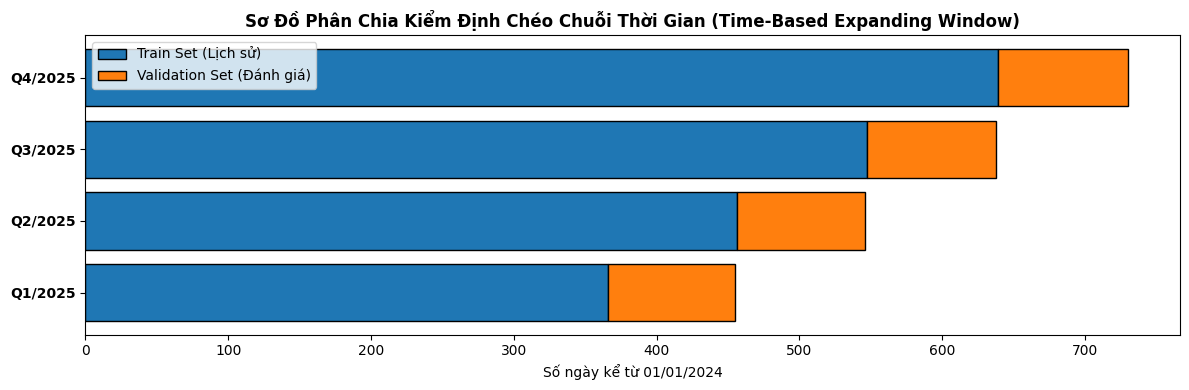

>>> HOÀN THÀNH STEP 4: ĐÃ PHÂN CHIA TIME-SERIES ĐẢM BẢO KHÔNG RÒ RỈ DỮ LIỆU!


In [2]:
fig, ax = plt.subplots(figsize=(12, 4))
quarters = list(EVAL_QUARTERS.keys())

for idx, (q, (s, e)) in enumerate(EVAL_QUARTERS.items()):
    val_start = pd.Timestamp(s)
    val_end = pd.Timestamp(e)
    # Train range
    ax.barh(idx, (val_start - pd.Timestamp("2024-01-01")).days, left=0, color="#1f77b4", edgecolor="black", label="Train Set (Lịch sử)" if idx==0 else "")
    # Validation range
    ax.barh(idx, (val_end - val_start).days, left=(val_start - pd.Timestamp("2024-01-01")).days, color="#ff7f0e", edgecolor="black", label="Validation Set (Đánh giá)" if idx==0 else "")

ax.set_yticks(range(len(quarters)))
ax.set_yticklabels(quarters, fontweight="bold")
ax.set_xlabel("Số ngày kể từ 01/01/2024")
ax.set_title("Sơ Đồ Phân Chia Kiểm Định Chéo Chuỗi Thời Gian (Time-Based Expanding Window)", fontweight="bold")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(">>> HOÀN THÀNH STEP 4: ĐÃ PHÂN CHIA TIME-SERIES ĐẢM BẢO KHÔNG RÒ RỈ DỮ LIỆU!")